# V0 — ResNet50 on RGB CIFAR-10 with validation
Use a stratified validation subset of the official training set to monitor training
and select the best epoch. The test set is evaluated only after training.
Keep the v0 RGB PNG paths, ImageNet normalization, randomly initialized conv1/fc,
and frozen ImageNet V1 backbone and BatchNorm statistics.
Start with a fresh kernel. Initialize once, then rerun the training cell to add epochs.


In [ ]:
from pathlib import Path
import json
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
# Experiment choices; preserve the selected checkpoint and current defaults.
CONFIG = {
    "checkpoint_name": None,  # None starts a new experiment.
    "batch_size": 32,
    "model_seed": 42,
    "loader_seed": 2,
    "split_seed": 42,
    "validation_fraction": 0.1,
    "num_classes": 10,
    "data_dir": "data/cifar-10_resized_YCbCr",
    "train_manifest": "output/manifest_train.json",
    "test_manifest": "output/manifest_test.json",
    "models_dir": "output/models",
}

CONFIG_NET = {
    "learning_rate": 0.01,
    "min_lr": 1e-5,
    "momentum": 0,
    "weight_decay": 0,
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
}

torch.manual_seed(CONFIG["model_seed"])
CHECKPOINT_NAME = CONFIG["checkpoint_name"]
# Local: run from root or notebooks/. In Colab mount Drive first and set
# PROJECT_ROOT to the folder containing data/, output/ and src/ml_setup/.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
import sys
SOURCE_ROOT = PROJECT_ROOT / "src"
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))
DATA_ROOT = PROJECT_ROOT / CONFIG["data_dir"]
TRAIN_MANIFEST = PROJECT_ROOT / CONFIG["train_manifest"]
TEST_MANIFEST = PROJECT_ROOT / CONFIG["test_manifest"]
MODELS_DIR = PROJECT_ROOT / CONFIG["models_dir"]
CHECKPOINT_TO_LOAD = MODELS_DIR / CHECKPOINT_NAME if CHECKPOINT_NAME else None
VERSION = "v0"
REPRESENTATION = "uncompressed-rgb-png-v0"
print("Device:",device, "\nDataset path:",DATA_ROOT)
#import hashlib
import random
from collections import Counter

EXPERIMENT = {"version": VERSION, "representation": REPRESENTATION, "scale": None}
SPLIT_PATH = PROJECT_ROOT / "output" / "splits" / (
    f"cifar10_train_val_{CONFIG['validation_fraction']:g}.json"
)
#def digest(value):
#    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":")).encode()).hexdigest()


Device: cuda 
Dataset path: C:\Users\Edward\Desktop\AARHUS\data\cifar-10_resized_YCbCr


In [3]:
# net parameters
BATCH_SIZE = CONFIG["batch_size"]
INITIAL_LR = CONFIG_NET["learning_rate"]
CHANNEL_MEAN = [0.485, 0.456, 0.406]
CHANNEL_STD = [0.229, 0.224, 0.225]
normalization_stats = dict(source="ImageNet", mean=CHANNEL_MEAN.copy(),
                           std=CHANNEL_STD.copy(), units="RGB float32 in [0,1]")

## Dataset and preprocessing
Reuse the manifests as label tables, mapping `.network.npz` names to `.png`.
Image paths are relative to the explicit RGB split directory, not the manifest directory.
No resize or crop: PNGs must already be RGB 224×224. Training alone uses horizontal flips.
ImageNet mean/std are a standard convention for the pretrained backbone, not universally
optimal RGB constants. Published CIFAR-10 statistics on 32×32 pixels need not describe
the resized dataset, particularly its standard deviation.


In [5]:

def make_or_load_split(manifest_path, split_path, fraction, seed):
    """"Split the training set into training and validation"""
    if not 0 < fraction < 1:
        raise ValueError("validation_fraction must be between 0 and 1")
    
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

    if manifest.get("split") != "train":
        raise ValueError("Split must be created from the official training manifest")
    
    records = {}
    for sample in manifest["samples"]:
        name = sample["file"]
        image_id = Path(name).stem
        if image_id in records:
            raise ValueError("Duplicate image ID")
        records[image_id] = sample["label"]
    identity = {"schema": "cifar10-stratified-v1", 
                "seed": seed,
                "validation_fraction": fraction, 
                "class_to_idx": manifest["class_to_idx"]}
    if split_path.exists():
        split = json.loads(split_path.read_text(encoding="utf-8"))
        if any(split.get(k) != v for k, v in identity.items()):
            raise ValueError("Saved split differs from dataset/configuration; do not overwrite it")
    else:
        rng = random.Random(seed)
        train_ids, val_ids = [], []
        for label in sorted(set(records.values())):
            """Take 10% of the data, for each class (label) that appears"""
            ids = sorted(i for i, y in records.items() if y == label)
            n_val = int(len(ids) * fraction + 0.5)
            rng.shuffle(ids)
            val_ids.extend(ids[:n_val])
            train_ids.extend(ids[n_val:])
        split = {**identity, "train_ids": sorted(train_ids), "val_ids": sorted(val_ids)}
        split_path.parent.mkdir(parents=True, exist_ok=True)
        with split_path.open("x", encoding="utf-8") as f:
            json.dump(split, f, indent=2)
    a, b = split["train_ids"], split["val_ids"]

    if (len(a) != len(set(a)) or len(b) != len(set(b))
            or set(a) & set(b) or set(a) | set(b) != set(records)):
        raise ValueError("Saved split must partition all training IDs exactly once")
    if not a or not b:
        raise ValueError("Training and validation subsets must be nonempty")
    for label in sorted(set(records.values())):
        total = sum(y == label for y in records.values())
        if sum(records[i] == label for i in b) != int(total * fraction + 0.5):
            raise ValueError("Saved partition is not stratified as configured")
    return split

split_for_validation = make_or_load_split(
    TRAIN_MANIFEST, SPLIT_PATH, CONFIG["validation_fraction"], CONFIG["split_seed"]
)
train_ids = split_for_validation["train_ids"]
val_ids = split_for_validation["val_ids"]
#SPLIT_SHA256 = digest(split_for_validation)
print("Split:", SPLIT_PATH)


Split: C:\Users\Edward\Desktop\AARHUS\output\splits\cifar10_train_val_0.1.json


In [6]:
class RGBDataset(Dataset):
    def __init__(self, manifest_path, image_root, split, transform, selected_ids=None):
        self.manifest_path = Path(manifest_path)
        self.image_root = Path(image_root)
        self.transform = transform

        # The hash identifies the label table when resuming a checkpoint.
        raw = self.manifest_path.read_bytes()
        manifest = json.loads(raw)

        if manifest.get("split") != split:
            raise ValueError("Manifest split does not match the requested split")
        if selected_ids is not None:
            wanted = set(selected_ids)
            rows = [row for row in manifest["samples"] if Path(row["file"]).stem in wanted]
            if len(rows) != len(wanted):
                raise ValueError("Missing or duplicate selected image IDs")
            manifest["samples"] = rows
        if not manifest["samples"]:
            raise ValueError("Empty dataset")
        self.idx_to_class = {index: name for name, index in manifest['class_to_idx'].items()}

        # Existing manifests list NPZs; the RGB files have the same image IDs.
        self.samples = [
            dict(file=row['file'].removesuffix('.network.npz') + '.png', label=row['label'])
            for row in manifest['samples']
        ]

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        row = self.samples[index]
        with Image.open(self.image_root / row['file']) as image:
            if image.mode != "RGB" or image.size != (224, 224):
                raise ValueError("Expected an RGB PNG with size 224 x 224")
            image = self.transform(image)
        return image, torch.tensor(row['label'], dtype=torch.long)

train_transform = transforms.Compose([
    transforms.ToTensor(), transforms.RandomHorizontalFlip(p=0.5),
    transforms.Normalize(CHANNEL_MEAN, CHANNEL_STD),
])
test_transform = transforms.Compose([
    transforms.ToTensor(), transforms.Normalize(CHANNEL_MEAN, CHANNEL_STD),
])
train_data = RGBDataset(TRAIN_MANIFEST, DATA_ROOT / 'train', 'train', train_transform, train_ids)
val_data = RGBDataset(TRAIN_MANIFEST, DATA_ROOT / 'train', 'train', test_transform, val_ids)
test_data = RGBDataset(TEST_MANIFEST, DATA_ROOT / 'test', 'test', test_transform)
# Both splits must interpret class indices in the same way.
if train_data.idx_to_class != test_data.idx_to_class:
    raise ValueError("Train/test class mappings differ")

data_context = dict(image_size=[3, 224, 224], batch_size=BATCH_SIZE,
                    augmentation="horizontal_flip_p0.5", conv1="random_trainable",
                    backbone="ImageNet1K_V1", batchnorm="not frozen",
                    normalization=normalization_stats)
print(f"Training: {len(train_data)}; test: {len(test_data)}")
print(f"Validation: {len(val_data)}")
print("Validation per class:", dict(sorted(Counter(s["label"] for s in val_data.samples).items())))


Training: 45000; test: 10000
Validation: 5000
Validation per class: {0: 500, 1: 500, 2: 500, 3: 500, 4: 500, 5: 500, 6: 500, 7: 500, 8: 500, 9: 500}


In [7]:
train_generator = torch.Generator().manual_seed(CONFIG["loader_seed"])
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True,
                          generator=train_generator, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Train: {len(train_loader)} batches; test: {len(test_loader)} batches")
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Validation: {len(val_loader)} batches")


Train: 1407 batches; test: 313 batches
Validation: 157 batches


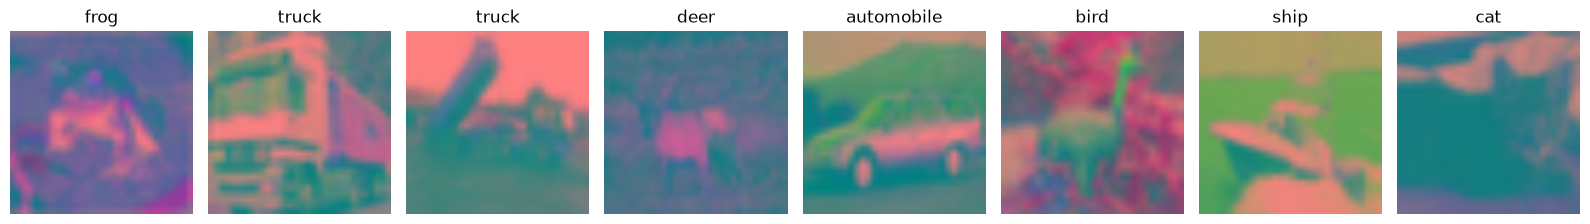

In [8]:
# Preview without consuming training-loader or augmentation RNG state.
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(123)
    previews = [train_data[i] for i in range(8)]
images = torch.stack([item[0] for item in previews])
labels = torch.stack([item[1] for item in previews])
assert images.shape == (8, 3, 224, 224) and torch.isfinite(images).all()
mean = torch.tensor(CHANNEL_MEAN).view(3, 1, 1)
std = torch.tensor(CHANNEL_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 8, figsize=(16, 3))
for ax, image, label in zip(axes, images, labels):
    ax.imshow((image * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(train_data.idx_to_class[label.item()])
    ax.axis('off')
plt.tight_layout()
plt.show()

## Model and frozen BatchNorm
BatchNorm normalizes intermediate features per channel. In training it uses batch
statistics and updates running mean/variance; in evaluation it uses the saved running
statistics. Its affine parameters (gamma/beta) are separately trainable.
Here requires_grad=False freezes gamma/beta, while the train() override keeps every
BatchNorm in eval mode to prevent running-statistic updates. Gradients still propagate
through the frozen backbone to conv1. This matches the compressed experiment.

In [10]:
#manifest_hashes = {name: hashlib.sha256(path.read_bytes()).hexdigest()
#                   for name, path in (("train", TRAIN_MANIFEST), ("test", TEST_MANIFEST))}
# Run once for a new experiment OR to restore a checkpoint.
# Do not rerun this cell when merely adding epochs in the current session.
import math
import torch.nn as nn
from ml_setup.models import CustomResNet50

INITIAL_LR = CONFIG_NET["learning_rate"]
torch.manual_seed(CONFIG["model_seed"])

checkpoint = None 
if CHECKPOINT_TO_LOAD is not None:
    checkpoint = torch.load(CHECKPOINT_TO_LOAD, map_location="cpu", weights_only=True)
    if checkpoint.get("schema") != "resnet-validation-v1":
        raise ValueError("Checkpoint missing validation split or using a different split")
    if checkpoint.get("version") != VERSION or checkpoint.get("representation") != REPRESENTATION:
        raise ValueError("Checkpoint version/representation differs (legacy checkpoints need explicit migration).")
    if checkpoint.get("scale") != EXPERIMENT["scale"]:
        raise ValueError("Checkpoint scale differs from the selected experiment.")

model = CustomResNet50(num_classes=CONFIG["num_classes"], pretrained=checkpoint is None,
                                      in_channels=3, freeze_backbone=False, freeze_batchnorm=True).to(device)
loss_fn = nn.CrossEntropyLoss()

"""
optimizer = torch.optim.SGD(
    (p for p in resnet_single_channel.parameters() if p.requires_grad), lr=INITIAL_LR
)
"""
optimizer = torch.optim.SGD(
    (p for p in model.parameters() if p.requires_grad),
    lr=INITIAL_LR,
    momentum=CONFIG_NET["momentum"],
    weight_decay=CONFIG_NET["weight_decay"]
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    factor=CONFIG_NET["scheduler_factor"],
    patience=CONFIG_NET["scheduler_patience"], 
    min_lr=CONFIG_NET["min_lr"],
    threshold=1e-4,
    threshold_mode="rel",
    cooldown=0
)

history = []
test_metrics = None
if checkpoint is not None:
    if checkpoint.get("split_info") != split_for_validation:
        raise ValueError("Checkpoint validation split differs")
    if checkpoint.get("data_context") != data_context:
        raise ValueError("Checkpoint data/model protocol differs")
    if checkpoint.get("manifest_hashes") != manifest_hashes:
        raise ValueError("Checkpoint label manifests differ")
    model.load_state_dict(checkpoint["model_state_dict"], strict=True)
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    history = checkpoint["history"]
    if checkpoint["completed_epochs"] != len(history):
        raise ValueError("Checkpoint epoch count and history disagree.")
    test_metrics = checkpoint.get("test_metrics")

print("Completed epochs:", len(history))
print("Total parameters:", sum(p.numel() for p in model.parameters()))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
model.eval()
with torch.inference_mode():
    check_logits = model(images[:2].to(device))
assert check_logits.shape == (min(2, len(images)), CONFIG["num_classes"])
assert torch.isfinite(check_logits).all()
if checkpoint is not None:
    torch.set_rng_state(checkpoint["torch_rng_state"])
    train_generator.set_state(checkpoint["loader_rng_state"])
    if torch.cuda.is_available() and checkpoint.get("cuda_rng_states"):
        if len(checkpoint["cuda_rng_states"]) == torch.cuda.device_count():
            torch.cuda.set_rng_state_all(checkpoint["cuda_rng_states"])
print("Model ready. Run the single training cell to add epochs.")


# Every run will generate a new folder
from datetime import datetime
from copy import deepcopy

RUN_DIR = MODELS_DIR / f"valid_v0_YCbCr_{datetime.now():%Y%m%d}"
RUN_DIR.mkdir(parents=True, exist_ok=False)
best_val_loss = checkpoint["best_val_loss"] if checkpoint else float("inf")
best_epoch = checkpoint["best_epoch"] if checkpoint else None
best_model_state = checkpoint["best_model_state_dict"] if checkpoint else None
print("Checkpoints:", RUN_DIR)


Completed epochs: 0
Total parameters: 23528522
Trainable parameters: 23528522
Model ready. Run the single training cell to add epochs.
Checkpoints: C:\Users\Edward\Desktop\AARHUS\output\models\valid_v0_YCbCr_20261023


In [12]:
from ml_setup.helper_functions import train_step, test_step, summarize_training_time


def save_checkpoint(filename):
    payload = {
        "schema": "resnet-validation-v1", **EXPERIMENT,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "num_classes": CONFIG["num_classes"], "completed_epochs": len(history),
        "history": history, "normalization": normalization_stats,
        "idx_to_class": train_data.idx_to_class,
        "split_info": split_for_validation,
        "data_context": data_context,
        #"manifest_hashes": manifest_hashes,
        "best_val_loss": best_val_loss, 
        "best_epoch": best_epoch,
        "best_model_state_dict": best_model_state,
        "test_metrics": test_metrics,
        "training_time": summarize_training_time(history),
        "torch_rng_state": torch.get_rng_state(),
        "loader_rng_state": train_generator.get_state(),
        "cuda_rng_states": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
    }
    destination = RUN_DIR / filename
    temporary = destination.with_suffix(".pth.partial")
    torch.save(payload, temporary)
    temporary.replace(destination)


## Training and validation
Each execution adds epochs and records training and validation loss/accuracy.
Keep the v0 fixed learning rate unless explicitly changed below.
Save best.pth when validation loss improves and last.pth after every epoch.


In [ ]:
NEW_LR = None  # Optional positive value; None preserves optimizer LR.
if NEW_LR is not None:
    if not math.isfinite(NEW_LR) or NEW_LR <= 0:
        raise ValueError("NEW_LR must be finite and positive")
    for group in optimizer.param_groups:
        group['lr'] = NEW_LR
print('Current learning rates:', [group['lr'] for group in optimizer.param_groups])

In [17]:
from tqdm.auto import tqdm
from timeit import default_timer as timer

ADDITIONAL_EPOCHS = 5
if not isinstance(ADDITIONAL_EPOCHS, int) or ADDITIONAL_EPOCHS < 1:
    raise ValueError("ADDITIONAL_EPOCHS must be positive")
start_epoch = len(history)
end_epoch = start_epoch + ADDITIONAL_EPOCHS
start_time = timer()
test_metrics = None
for epoch in tqdm(range(start_epoch + 1, end_epoch + 1)):
    print(f"\nEpoch {epoch}/{end_epoch}")
    metrics = train_step(model, train_loader, loss_fn, optimizer, device)
    print("Validation (the shared helper labels this evaluation 'Test'):")
    val_metrics = test_step(model, val_loader, loss_fn, device,
                            num_classes=CONFIG["num_classes"])
    if not math.isfinite(val_metrics["loss"]):
        raise ValueError("Non-finite validation loss")
    history.append({"epoch": epoch, "loss": float(metrics["loss"]),
                    "accuracy": float(metrics["accuracy"]),
                    "val_loss": float(val_metrics["loss"]),
                    "val_accuracy": float(val_metrics["accuracy"]),
                    "validation_seconds": val_metrics["evaluation_seconds"],
                    "lr": float(optimizer.param_groups[0]["lr"]),
                    "training_seconds": metrics["training_seconds"],
                    "training_device": str(device)})
    if val_metrics["loss"] < best_val_loss:
        best_val_loss = float(val_metrics["loss"])
        best_epoch = epoch
        # Independent CPU copy: later training cannot change the best weights.
        best_model_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        save_checkpoint("best.pth")
        print(f"New best validation loss: {best_val_loss:.5f} (epoch {best_epoch})")
    save_checkpoint("last.pth")
print(f"Completed: {len(history)} epochs; elapsed: {timer() - start_time:.1f}s")
print("Best epoch:", best_epoch)
print("Resume with checkpoint_name =", str((RUN_DIR / "last.pth").relative_to(MODELS_DIR)))


  0%|          | 0/5 [00:00<?, ?it/s]


Epoch 6/10
Train loss: 0.09505 | Train accuracy: 96.75%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 0.37003 | Test accuracy: 89.98%

Epoch 7/10
Train loss: 0.07694 | Train accuracy: 97.35%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 0.16417 | Test accuracy: 94.82%
New best validation loss: 0.16417 (epoch 7)

Epoch 8/10
Train loss: 0.06418 | Train accuracy: 97.82%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 0.16129 | Test accuracy: 95.14%
New best validation loss: 0.16129 (epoch 8)

Epoch 9/10
Train loss: 0.05036 | Train accuracy: 98.34%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 0.18178 | Test accuracy: 94.66%

Epoch 10/10
Train loss: 0.04431 | Train accuracy: 98.46%
Validation (the shared helper labels this evaluation 'Test'):
Test loss: 0.17668 | Test accuracy: 95.20%
Completed: 10 epochs; elapsed: 2464.0s
Best epoch: 8
Resume with checkpoint_name = valid_v0_YCbCr_202

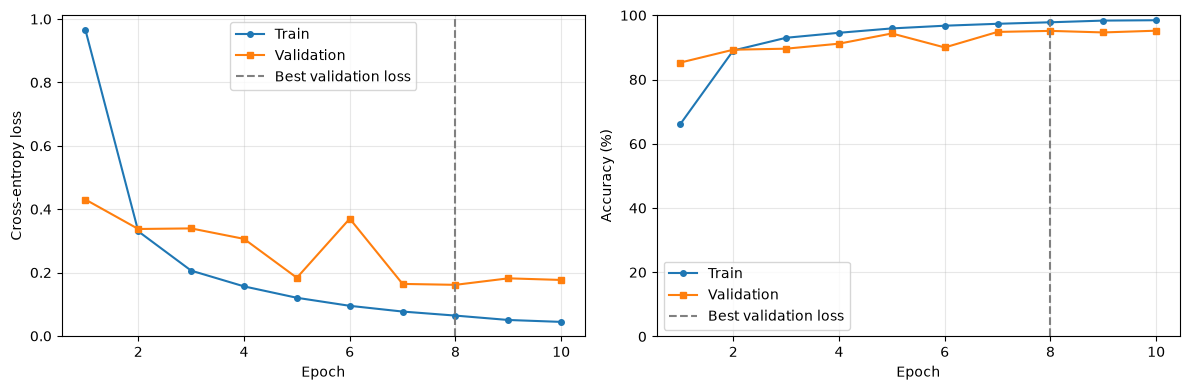

In [18]:
if not history:
    raise ValueError("Train or load a validation checkpoint first")
epochs = [row["epoch"] for row in history]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, key, title in zip(axes, ("loss", "accuracy"), ("Cross-entropy loss", "Accuracy (%)")):
    ax.plot(epochs, [r[key] for r in history], label="Train", marker="o", markersize=4)
    ax.plot(epochs, [r["val_" + key] for r in history], label="Validation", marker="s", markersize=4)
    if best_epoch is not None:
        ax.axvline(best_epoch, linestyle="--", color="gray", label="Best validation loss")
    ax.set(xlabel="Epoch", ylabel=title)
    ax.grid(alpha=0.3)
    ax.legend()
axes[1].set_ylim(0, 100)
fig.tight_layout()
plt.show()


## Final held-out test evaluation
Evaluate the epoch with the lowest validation loss.


Best model (epoch 8) evaluation on test set:
Validation loss: 0.16129; accuracy: 95.14%
Test loss: 0.18104 | Test accuracy: 94.95%


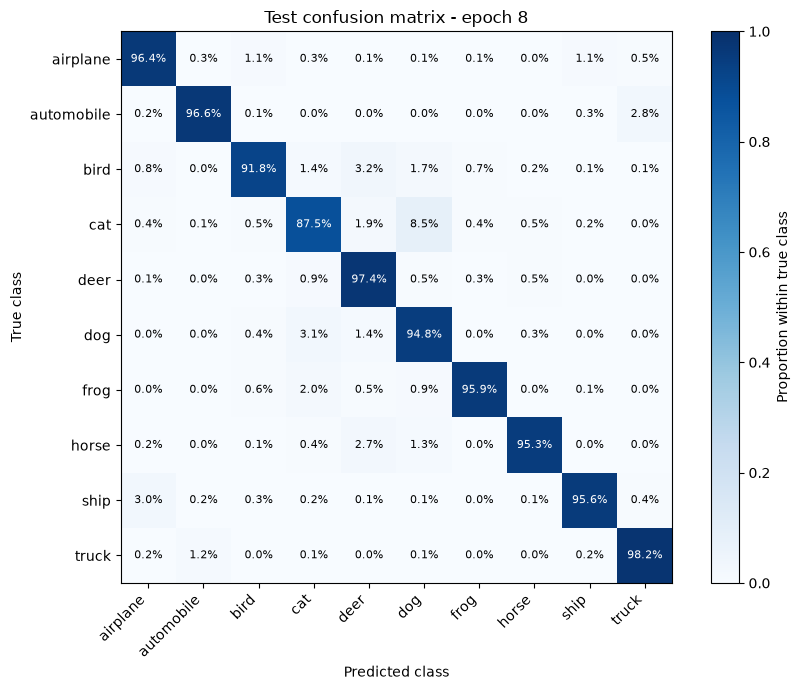

In [19]:
if best_model_state is None or best_epoch is None:
    raise ValueError("Train or restore a validation checkpoint before evaluation")
evaluation_model = deepcopy(model).cpu()
evaluation_model.load_state_dict(best_model_state)
evaluation_model.to(device)
# Rows = true classes, columns = predicted classes. Each supported row sums to 1.
import numpy as np

num_classes = CONFIG["num_classes"]
class_names = [test_data.idx_to_class[i] for i in range(num_classes)]

print(f"Best model (epoch {best_epoch}) evaluation on test set:")
print(f"Validation loss: {best_val_loss:.5f}; accuracy: {history[best_epoch - 1]['val_accuracy'] / 100:.2%}")

# set "model" instead of "evaluation_model" to evaluate the last checkpoint instead of the best one.
evaluation = test_step(evaluation_model, test_loader, loss_fn, device,
                       num_classes=num_classes)

confusion_counts = np.asarray(evaluation["confusion_counts"], dtype=np.int64)
support = confusion_counts.sum(axis=1, keepdims=True)
confusion_proportions = np.divide(confusion_counts, support,
    out=np.zeros_like(confusion_counts, dtype=np.float64), where=support != 0)
test_metrics = {"epoch": best_epoch, "loss": evaluation["loss"],
    "accuracy": evaluation["accuracy"],
    "confusion_counts": confusion_counts.tolist(),
    "confusion_proportions": confusion_proportions.tolist()}
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(confusion_proportions, cmap="Blues", vmin=0, vmax=1)
fig.colorbar(im, ax=ax, label="Proportion within true class")
ax.set(xticks=range(num_classes), yticks=range(num_classes),
       xticklabels=class_names, yticklabels=class_names,
       xlabel="Predicted class", ylabel="True class",
       title=f"Test confusion matrix - epoch {best_epoch}")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
for i in range(num_classes):
    for j in range(num_classes):
        value = confusion_proportions[i, j]
        label = f"{value:.1%}" if support[i, 0] else "N/A"
        ax.text(j, i, label, ha="center", va="center",
                color="white" if value > 0.5 else "black", fontsize=8)
fig.tight_layout()
plt.show()
# Diagonal = recall per class. N/A means that class is absent from this split.

del evaluation_model


In [21]:
# update last.pth with the test metrics as well
if not history or best_model_state is None:
    raise ValueError("No completed validation training to save")
save_checkpoint("last.pth")
print("Saved:", RUN_DIR / "last.pth")


Saved: C:\Users\Edward\Desktop\AARHUS\output\models\valid_v0_YCbCr_20261023\last.pth


## Resume
Set CONFIG["checkpoint_name"] to the path relative to output/models, for example
`valid_v0_<timestamp>/last.pth`, and run setup in a fresh kernel.
Initialization restores the current model, optimizer, history, best weights and RNG states.
Rerun the training cell to add epochs, or evaluate the best weights directly.
Legacy v0 checkpoints trained without validation are intentionally rejected because
their training data include the validation subset.
The shared split uses original manifest IDs, including the `.network` suffix;
PNG filename conversion happens only inside RGBDataset.
